# Manual Validation Analysis

This notebook reads the manual topic validation results from the Streamlit app, merges them with the model reference file, and prepares both topic-level and review-level validation outputs.

Inputs:

- `data/manual_validation/manual_validation_scores.csv`
- `data/manual_validation/manual_validation_model_reference.csv`
- final review-level dataframe: `reviews`

Outputs to create later:

- topic-level validation dataframe
- review-level dataframe with manual validation fields merged back on
- agreement metrics and validation plots

### Import Data and Merge

In [53]:
# ============================================================
# Manual Validation Analysis Setup
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

reviews = pd.read_csv("data/reviews_with_dimensions.csv")

DIM_ORDER = [
    "Availability",
    "Accessibility",
    "Accommodation",
    "Affordability",
    "Acceptability",
]

VALIDATION_DIR = Path("data/manual_validation")

SCORES_OUTPUT_PATH = VALIDATION_DIR / "manual_validation_scores.csv"
MODEL_REFERENCE_PATH = VALIDATION_DIR / "manual_validation_model_reference.csv"

TOPIC_VALIDATION_OUTPUT_PATH = VALIDATION_DIR / "manual_validation_topic_results.csv"
REVIEWS_VALIDATION_OUTPUT_PATH = VALIDATION_DIR / "reviews_with_manual_validation.csv"

In [54]:
# ============================================================
# Load manual scores and model reference
# ============================================================

if not MODEL_REFERENCE_PATH.exists():
    raise FileNotFoundError(f"Model reference file not found: {MODEL_REFERENCE_PATH}")

if not SCORES_OUTPUT_PATH.exists():
    raise FileNotFoundError(
        f"Manual scores file not found: {SCORES_OUTPUT_PATH}\n"
        "Run the Streamlit app and save at least one topic annotation first."
    )

model_reference = pd.read_csv(MODEL_REFERENCE_PATH)
manual_scores = pd.read_csv(SCORES_OUTPUT_PATH)

# Ensure Topic IDs are clean integers
model_reference["Topic"] = model_reference["Topic"].astype(int)
manual_scores["Topic"] = manual_scores["Topic"].astype(int)

print("=== Loaded validation files ===")
print(f"Model reference rows: {len(model_reference):,}")
print(f"Manual score rows:    {len(manual_scores):,}")
print()
print(f"Model reference topics: {model_reference['Topic'].nunique():,}")
print(f"Manually scored topics: {manual_scores['Topic'].nunique():,}")

=== Loaded validation files ===
Model reference rows: 59
Manual score rows:    15

Model reference topics: 59
Manually scored topics: 15


In [55]:
# ============================================================
# Check manual scoring completeness
# ============================================================

model_topics = set(model_reference["Topic"])
scored_topics = set(manual_scores["Topic"])

missing_scored_topics = sorted(model_topics - scored_topics)
extra_scored_topics = sorted(scored_topics - model_topics)

print("=== Manual scoring completeness ===")
print(f"Total topics in model reference: {len(model_topics):,}")
print(f"Topics scored so far:            {len(scored_topics):,}")
print(f"Topics not yet scored:           {len(missing_scored_topics):,}")
print(f"Extra scored topics:             {len(extra_scored_topics):,}")

if missing_scored_topics:
    print("\nTopics not yet scored:")
    print(missing_scored_topics)

if extra_scored_topics:
    print("\nWARNING: Manual scores contain topics not in model reference:")
    print(extra_scored_topics)

if "manual_topic_status" in manual_scores.columns:
    print("\nManual topic status counts:")
    print(manual_scores["manual_topic_status"].value_counts(dropna=False))

=== Manual scoring completeness ===
Total topics in model reference: 59
Topics scored so far:            15
Topics not yet scored:           44
Extra scored topics:             0

Topics not yet scored:
[15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58]

Manual topic status counts:
manual_topic_status
valid      9
invalid    6
Name: count, dtype: int64


In [56]:
# ============================================================
# Merge manual scores with model reference
# ============================================================

validation_topics = model_reference.merge(
    manual_scores,
    on="Topic",
    how="left",
    validate="one_to_one",
)

print("=== Topic-level validation dataframe ===")
print(f"Rows: {len(validation_topics):,}")
print(f"Unique topics: {validation_topics['Topic'].nunique():,}")
print()

n_with_scores = validation_topics["manual_topic_status"].notna().sum()
n_without_scores = validation_topics["manual_topic_status"].isna().sum()

print(f"Topics with manual annotations:    {n_with_scores:,}")
print(f"Topics without manual annotations: {n_without_scores:,}")

validation_topics.head()

=== Topic-level validation dataframe ===
Rows: 59
Unique topics: 59

Topics with manual annotations:    15
Topics without manual annotations: 44


,Topic,n_reviews,Name,Representation,OpenAI,pred_dim,pred_prob,pred_dim2,pred_prob2,pred_dim3,...,random_review_3,manual_topic_status,manual_invalid_reason,manual_Availability,manual_Accessibility,manual_Accommodation,manual_Affordability,manual_Acceptability,manual_notes,last_updated
0,0,1106,0_meat_meats_meat department_butcher,"['meat', 'meats', 'meat department', 'butcher'...",['Meat Department Quality'],Affordability,0.403097,Availability,0.285758,NaN,...,"Variety of meats, produce and everyday needs. ...",valid,NaN,2.0,0.0,0.0,2.0,3.0,NaN,2026-05-11T13:52:43
1,1,1718,1_groceries_grocery_grocery store_place,"['groceries', 'grocery', 'grocery store', 'pla...",['Grocery Shopping Preferences'],Affordability,0.454898,NaN,NaN,NaN,...,Great place and prices for all your grocery ne...,invalid,too_generic,0.0,0.0,0.0,0.0,0.0,NaN,2026-05-11T13:53:28
2,2,788,2_experience_place_visit_good experience,"['experience', 'place', 'visit', 'good experie...",['Positive Visit Experiences'],Accessibility,0.269142,Availability,0.259152,Acceptability,...,Pretty new and nice Harris Teeter. Good location.,invalid,too_generic,0.0,0.0,0.0,0.0,0.0,NaN,2026-05-11T13:54:21
3,3,1237,3_prices_high_quality_low,"['prices', 'high', 'quality', 'low', 'prices g...",['Price Perception'],Affordability,0.579430,NaN,NaN,NaN,...,Decent prices and products.,valid,NaN,0.0,0.0,0.0,3.0,2.0,NaN,2026-05-11T13:54:55
4,4,1296,4_store_prices_great store_nice store,"['store', 'prices', 'great store', 'nice store...",['Consumer behavior in retail'],Accommodation,0.254765,Affordability,0.249886,Acceptability,...,Good stuff and really cheap. I always save mon...,valid,NaN,0.0,0.0,0.0,3.0,2.0,NaN,2026-05-11T13:55:12


In [57]:
# ============================================================
# Add manual scoring status flags
# ============================================================

validation_topics["manual_scored"] = validation_topics["manual_topic_status"].notna()

validation_topics["manual_is_valid"] = (
    validation_topics["manual_topic_status"].eq("valid")
)

validation_topics["manual_is_invalid"] = (
    validation_topics["manual_topic_status"].eq("invalid")
)

validation_topics["manual_needs_review"] = (
    validation_topics["manual_topic_status"].eq("needs_review")
)

print("=== Manual scoring flags ===")
print(validation_topics[
    [
        "manual_scored",
        "manual_is_valid",
        "manual_is_invalid",
        "manual_needs_review",
    ]
].sum())

=== Manual scoring flags ===
manual_scored          15
manual_is_valid         9
manual_is_invalid       6
manual_needs_review     0
dtype: int64


In [58]:
# ============================================================
# Merge manual validation results back onto review-level data
# ============================================================

reviews_with_validation = reviews.copy()

# Create integer Topic column for merging.
# Using pandas nullable Int64 keeps missing topic values as <NA>.
reviews_with_validation["Topic"] = reviews_with_validation["topic"].astype("Int64")

# Choose which topic-level validation columns to merge back onto reviews.
# Keep this fairly focused so the review-level dataframe does not get too huge.
manual_merge_cols = [
    "Topic",
    "manual_topic_status",
    "manual_invalid_reason",
    "manual_Availability",
    "manual_Accessibility",
    "manual_Accommodation",
    "manual_Affordability",
    "manual_Acceptability",
    "manual_notes",
    "last_updated",
    "manual_scored",
    "manual_is_valid",
    "manual_is_invalid",
    "manual_needs_review",
]

# Keep only columns that actually exist, so this works with partial/older files.
manual_merge_cols = [
    col for col in manual_merge_cols
    if col in validation_topics.columns
]

reviews_with_validation = reviews_with_validation.merge(
    validation_topics[manual_merge_cols],
    on="Topic",
    how="left",
    validate="many_to_one",
)

reviews_with_validation = reviews_with_validation.drop(columns=["Topic"])

print("=== Review-level dataframe with manual validation ===")
print(f"Rows: {len(reviews_with_validation):,}")
print(f"Columns: {reviews_with_validation.shape[1]:,}")
print()

print("Manual topic status counts at review level:")
print(reviews_with_validation["manual_topic_status"].value_counts(dropna=False))



=== Review-level dataframe with manual validation ===
Rows: 35,779
Columns: 76

Manual topic status counts at review level:
manual_topic_status
NaN        21184
valid       8183
invalid     6412
Name: count, dtype: int64


In [59]:
# ============================================================
# Save merged validation outputs
# ============================================================

#validation_topics.to_csv(TOPIC_VALIDATION_OUTPUT_PATH, index=False)
#reviews_with_validation.to_csv(REVIEWS_VALIDATION_OUTPUT_PATH, index=False)

print("Saved topic-level validation results to:")
print(TOPIC_VALIDATION_OUTPUT_PATH)



Saved topic-level validation results to:
data\manual_validation\manual_validation_topic_results.csv


## Derive Manual Labels and Prepare Validation Evaluation Set

Manual labels are derived from the independent 0–3 relevance scores assigned during manual validation.

For each topic:

1. Find the maximum manual relevance score across the five dimensions.
2. If the maximum score is less than 2, mark the topic as `unclear`.
3. If the maximum score is 2 or 3, assign all dimensions tied for the maximum score.
4. If four or more dimensions are tied for the maximum score, flag the topic as `broad`.

This produces a manual multilabel target set that can be compared to the model's predicted dimension labels and probability rankings.

In [60]:
# ============================================================
# Derive manual label sets from 0-3 manual scores
# ============================================================

manual_score_cols = [f"manual_{d}" for d in DIM_ORDER]

# Make sure manual score columns are numeric
for col in manual_score_cols:
    if col in validation_topics.columns:
        validation_topics[col] = pd.to_numeric(validation_topics[col], errors="coerce")

def derive_manual_labels(row, dims=DIM_ORDER):
    """
    Derive manual label set from 0-3 manual scores.

    Rule:
    - If topic is not manually scored, return missing labels.
    - If max score < 2, return empty label set and status 'unclear'.
    - Otherwise, labels are all dimensions tied for the highest score.
    - If 4+ labels tie for highest score, status is 'broad'.
    """
    if not row.get("manual_scored", False):
        return pd.Series({
            "manual_max_score": np.nan,
            "manual_label_set": tuple(),
            "manual_n_labels": 0,
            "manual_label_status": "not_scored",
        })

    scores = {
        dim: row.get(f"manual_{dim}", np.nan)
        for dim in dims
    }

    # Remove missing scores
    scores = {
        dim: score
        for dim, score in scores.items()
        if pd.notna(score)
    }

    if len(scores) == 0:
        return pd.Series({
            "manual_max_score": np.nan,
            "manual_label_set": tuple(),
            "manual_n_labels": 0,
            "manual_label_status": "not_scored",
        })

    max_score = max(scores.values())

    if max_score < 2:
        return pd.Series({
            "manual_max_score": max_score,
            "manual_label_set": tuple(),
            "manual_n_labels": 0,
            "manual_label_status": "unclear",
        })

    labels = tuple([
        dim for dim, score in scores.items()
        if score == max_score
    ])

    if len(labels) >= 4:
        label_status = "broad"
    else:
        label_status = "valid"

    return pd.Series({
        "manual_max_score": max_score,
        "manual_label_set": labels,
        "manual_n_labels": len(labels),
        "manual_label_status": label_status,
    })


manual_label_results = validation_topics.apply(derive_manual_labels, axis=1)

validation_topics = pd.concat(
    [validation_topics, manual_label_results],
    axis=1
)

print("=== Manual label status counts ===")
print(validation_topics["manual_label_status"].value_counts(dropna=False))

print("\n=== Number of manual labels per topic ===")
print(validation_topics["manual_n_labels"].value_counts(dropna=False).sort_index())

=== Manual label status counts ===
manual_label_status
not_scored    44
valid          9
unclear        6
Name: count, dtype: int64

=== Number of manual labels per topic ===
manual_n_labels
0    50
1     9
Name: count, dtype: int64


In [61]:
# ============================================================
# Derive model label sets and ranked model outputs
# ============================================================

model_prob_cols = [f"{d}_p" for d in DIM_ORDER]

def derive_model_label_set(row):
    """
    Construct model label set from pred_dim, pred_dim2, pred_dim3.
    Drops missing secondary/tertiary labels.
    """
    labels = []

    for col in ["pred_dim", "pred_dim2", "pred_dim3"]:
        value = row.get(col, np.nan)
        if pd.notna(value) and value != "":
            labels.append(value)

    return tuple(labels)


def derive_model_ranked_dims(row, dims=DIM_ORDER):
    """
    Return all dimensions ranked by model probability, highest to lowest.
    """
    probs = {
        dim: row.get(f"{dim}_p", np.nan)
        for dim in dims
    }

    probs = {
        dim: prob
        for dim, prob in probs.items()
        if pd.notna(prob)
    }

    ranked = sorted(probs, key=probs.get, reverse=True)
    return tuple(ranked)


validation_topics["model_label_set"] = validation_topics.apply(
    derive_model_label_set,
    axis=1
)

validation_topics["model_n_labels"] = validation_topics["model_label_set"].apply(len)

validation_topics["model_ranked_dims"] = validation_topics.apply(
    derive_model_ranked_dims,
    axis=1
)

print("=== Model label counts ===")
print(validation_topics["model_n_labels"].value_counts(dropna=False).sort_index())

validation_topics[
    [
        "Topic",
        "manual_topic_status",
        "manual_label_status",
        "manual_label_set",
        "model_label_set",
        "model_ranked_dims",
    ]
].head()

=== Model label counts ===
model_n_labels
1    28
2     6
3    25
Name: count, dtype: int64


,Topic,manual_topic_status,manual_label_status,manual_label_set,model_label_set,model_ranked_dims
0,0,valid,valid,"(Acceptability,)","(Affordability, Availability)","(Affordability, Availability, Acceptability, A..."
1,1,invalid,unclear,(),"(Affordability,)","(Affordability, Availability, Accommodation, A..."
2,2,invalid,unclear,(),"(Accessibility, Availability, Acceptability)","(Accessibility, Availability, Acceptability, A..."
3,3,valid,valid,"(Affordability,)","(Affordability,)","(Affordability, Accommodation, Acceptability, ..."
4,4,valid,valid,"(Affordability,)","(Accommodation, Affordability, Acceptability)","(Accommodation, Affordability, Acceptability, ..."


In [62]:
# ============================================================
# Define evaluation sets
# ============================================================

# Main evaluation set:
# - topic manually scored
# - manually marked valid
# - manual labels are valid or broad
#   broad topics are included here because they are valid topics,
#   but flagged for interpretation.
eval_topics = validation_topics[
    validation_topics["manual_scored"]
    & validation_topics["manual_topic_status"].eq("valid")
    & validation_topics["manual_label_status"].isin(["valid", "broad"])
].copy()

# Stricter subset excluding broad manual labels
eval_topics_strict = eval_topics[
    eval_topics["manual_label_status"].eq("valid")
].copy()

print("=== Evaluation set summary ===")
print(f"All topics in reference:          {len(validation_topics):,}")
print(f"Main evaluation topics:           {len(eval_topics):,}")
print(f"Strict non-broad eval topics:     {len(eval_topics_strict):,}")

print("\nMain evaluation manual label status counts:")
print(eval_topics["manual_label_status"].value_counts(dropna=False))

print("\nMain evaluation model label count distribution:")
print(eval_topics["model_n_labels"].value_counts(dropna=False).sort_index())

=== Evaluation set summary ===
All topics in reference:          59
Main evaluation topics:           9
Strict non-broad eval topics:     9

Main evaluation manual label status counts:
manual_label_status
valid    9
Name: count, dtype: int64

Main evaluation model label count distribution:
model_n_labels
1    4
2    1
3    4
Name: count, dtype: int64


In [63]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35779 entries, 0 to 35778
Data columns (total 63 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   address                  35779 non-null  object 
 1   categoryName             35779 non-null  object 
 2   cid                      35779 non-null  uint64 
 3   city                     35779 non-null  object 
 4   countryCode              35779 non-null  object 
 5   error                    0 non-null      float64
 6   fid                      35779 non-null  object 
 7   isAdvertisement          35779 non-null  bool   
 8   isLocalGuide             35779 non-null  bool   
 9   language                 35779 non-null  object 
 10  likesCount               35779 non-null  float64
 11  location/lat             35779 non-null  float64
 12  location/lng             35779 non-null  float64
 13  name                     35779 non-null  object 
 14  originalLanguage      

## Evaluation

### Top K Accuracy

In [64]:
# ============================================================
# Top-k accuracy
# ============================================================

def top_k_hit(manual_labels, model_ranked_dims, k):
    """
    Multilabel top-k hit.

    Returns True if any manual label appears in the model's top-k dimensions.
    """
    manual_set = set(manual_labels)
    top_k_set = set(model_ranked_dims[:k])

    if len(manual_set) == 0:
        return np.nan

    return len(manual_set & top_k_set) > 0


topk_results = []

for k in [1, 2, 3, 4, 5]:
    col = f"top{k}_hit"

    eval_topics[col] = eval_topics.apply(
        lambda row: top_k_hit(
            row["manual_label_set"],
            row["model_ranked_dims"],
            k,
        ),
        axis=1,
    )

    acc = eval_topics[col].mean()

    topk_results.append({
        "k": k,
        "top_k_accuracy": acc,
        "n_topics": eval_topics[col].notna().sum(),
    })

topk_df = pd.DataFrame(topk_results)

topk_df

,k,top_k_accuracy,n_topics
0,1,0.333333,9
1,2,0.666667,9
2,3,1.000000,9
3,4,1.000000,9
4,5,1.000000,9


### Accuracy Heatmap

In [65]:
# ============================================================
# Manual label vs model primary prediction heatmap table
# ============================================================

heatmap_rows = []

for _, row in eval_topics.iterrows():
    for manual_label in row["manual_label_set"]:
        heatmap_rows.append({
            "Topic": row["Topic"],
            "manual_label": manual_label,
            "model_primary_label": row["pred_dim"],
        })

heatmap_long = pd.DataFrame(heatmap_rows)

confusion_counts = pd.crosstab(
    heatmap_long["manual_label"],
    heatmap_long["model_primary_label"],
).reindex(index=DIM_ORDER, columns=DIM_ORDER, fill_value=0)

confusion_counts

model_primary_label,Availability,Accessibility,Accommodation,Affordability,Acceptability
manual_label,,,,,
Availability,0,0,1,0,0
Accessibility,0,1,0,0,0
Accommodation,0,0,0,0,0
Affordability,0,0,1,1,0
Acceptability,0,0,0,4,1


In [66]:
# Row-normalized heatmap:
# Of topics manually coded to each dimension, where did the model's primary label go?
confusion_row_norm = confusion_counts.div(
    confusion_counts.sum(axis=1).replace(0, np.nan),
    axis=0,
)

confusion_row_norm

model_primary_label,Availability,Accessibility,Accommodation,Affordability,Acceptability
manual_label,,,,,
Availability,0.0,0.0,1.0,0.0,0.0
Accessibility,0.0,1.0,0.0,0.0,0.0
Accommodation,NaN,NaN,NaN,NaN,NaN
Affordability,0.0,0.0,0.5,0.5,0.0
Acceptability,0.0,0.0,0.0,0.8,0.2


In [67]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_accuracy_heatmaps(
    compare: pd.DataFrame,
    dims=("Availability", "Accessibility", "Accommodation", "Affordability", "Acceptability"),
    manual_label_col: str = "manual_label_set",
    pred_col: str = "pred_dim",
    include_broad: bool = True,
    status_col: str = "manual_label_status",
    cmap: str = "Greens",
):
    """
    Plot manual-vs-model accuracy heatmaps.

    True labels are derived from `manual_label_set`, which may contain one or
    more manual labels per topic. Multilabel topics are exploded so that each
    manual label contributes one row to the confusion matrix.

    Predicted label is the model's primary predicted dimension, `pred_dim`.
    """
    dims = list(dims)

    comp = compare.copy()

    if not include_broad and status_col in comp.columns:
        comp = comp[comp[status_col] != "broad"].copy()

    comp = comp[comp[pred_col].isin(dims)].copy()

    def labels_to_list(x):
        if isinstance(x, (list, tuple, set)):
            return list(x)
        if pd.isna(x):
            return []
        if isinstance(x, str):
            cleaned = (
                x.replace("(", "")
                 .replace(")", "")
                 .replace("[", "")
                 .replace("]", "")
                 .replace("'", "")
                 .replace('"', "")
            )
            labels = [lab.strip() for lab in cleaned.split(",") if lab.strip()]
            return [lab for lab in labels if lab in dims]
        return []

    comp["_manual_labels_list"] = comp[manual_label_col].apply(labels_to_list)

    exploded = comp.explode("_manual_labels_list").rename(
        columns={"_manual_labels_list": "manual_label"}
    )

    exploded = exploded[
        exploded["manual_label"].isin(dims)
        & exploded[pred_col].isin(dims)
    ].copy()

    y_true = exploded["manual_label"].to_numpy()
    y_pred = exploded[pred_col].to_numpy()

    cm = confusion_matrix(y_true, y_pred, labels=dims)

    with np.errstate(divide="ignore", invalid="ignore"):
        row_sums = cm.sum(axis=1, keepdims=True)
        cm_norm = np.divide(
            cm,
            row_sums,
            out=np.zeros_like(cm, dtype=float),
            where=row_sums != 0,
        )

    # --------------------------------------------------------
    # Heatmap 1: row-normalized confusion matrix
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6.5, 5.5))

    im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1)

    ax.set_xticks(np.arange(len(dims)))
    ax.set_yticks(np.arange(len(dims)))

    ax.set_xticklabels(dims, rotation=45, ha="right")
    ax.set_yticklabels(dims)

    ax.set_xlabel("Model primary prediction")
    ax.set_ylabel("Manual label")
    ax.set_title("Accuracy Heatmap\n(row-normalized manual vs model labels)")

    for i in range(cm_norm.shape[0]):
        for j in range(cm_norm.shape[1]):
            ax.text(
                j,
                i,
                f"{cm_norm[i, j]:.2f}\n(n={cm[i, j]})",
                ha="center",
                va="center",
                fontsize=8,
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Row-normalized proportion")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Heatmap 2: per-class accuracy
    # --------------------------------------------------------
    per_class_acc = np.diag(cm_norm)

    fig2, ax2 = plt.subplots(figsize=(7, 2.2))

    im2 = ax2.imshow(
        per_class_acc[np.newaxis, :],
        cmap=cmap,
        vmin=0,
        vmax=1,
        aspect="auto",
    )

    ax2.set_xticks(np.arange(len(dims)))
    ax2.set_xticklabels(dims, rotation=45, ha="right")
    ax2.set_yticks([])

    ax2.set_title("Per-class accuracy")
    ax2.set_xlabel("Manual dimension")

    for j, v in enumerate(per_class_acc):
        ax2.text(
            j,
            0,
            f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )

    fig2.colorbar(im2, ax=ax2, fraction=0.06, pad=0.04, label="Accuracy")
    fig2.subplots_adjust(bottom=0.38, right=0.88)

    plt.show()

    return {
        "labels": dims,
        "confusion_matrix": cm,
        "confusion_matrix_row_normalized": cm_norm,
        "per_class_accuracy": per_class_acc,
        "exploded_compare": exploded,
        "n_topics_input": int(len(compare)),
        "n_exploded_rows_used": int(len(exploded)),
    }

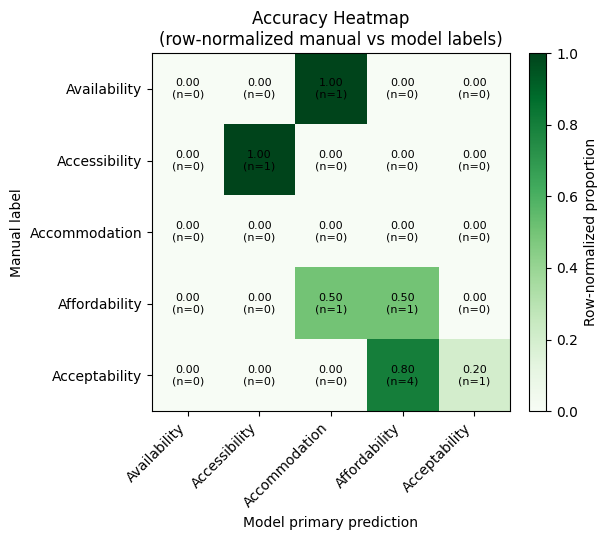

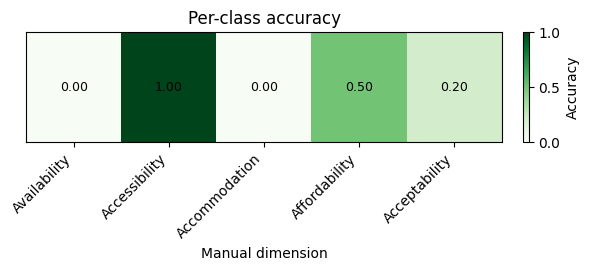

array([0. , 1. , 0. , 0.5, 0.2])

In [68]:
res = plot_accuracy_heatmaps(eval_topics)

res["per_class_accuracy"]

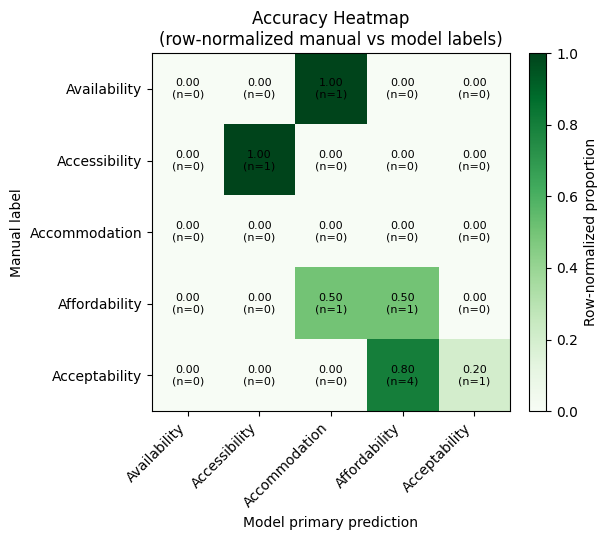

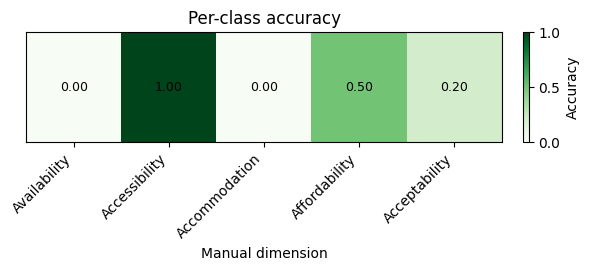

array([0. , 1. , 0. , 0.5, 0.2])

In [69]:
res_strict = plot_accuracy_heatmaps(
    eval_topics,
    include_broad=False,
)

res_strict["per_class_accuracy"]

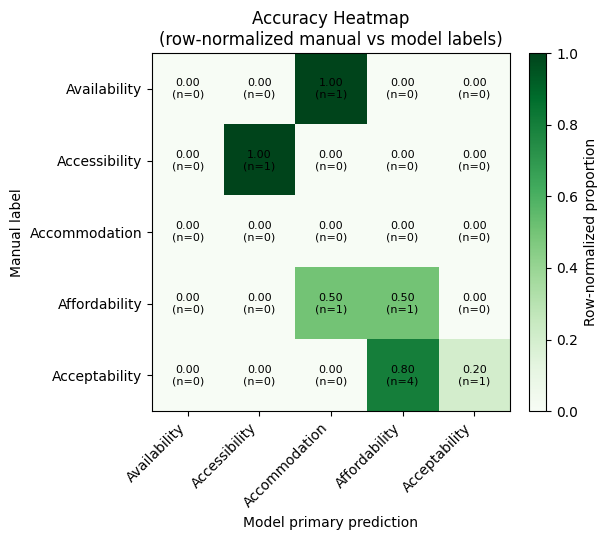

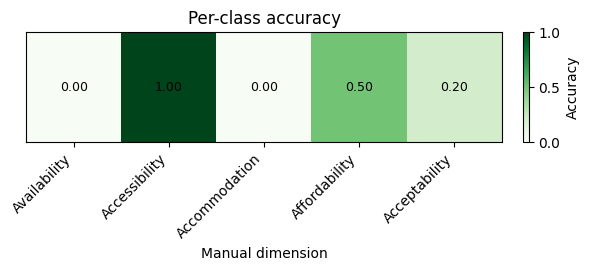

array([0. , 1. , 0. , 0.5, 0.2])

In [70]:
single_label_eval_topics = eval_topics[
    eval_topics["manual_n_labels"].eq(1)
].copy()

res_single = plot_accuracy_heatmaps(single_label_eval_topics)

res_single["per_class_accuracy"]

### ROC-AUC Accuracy

ROC-AUC By Dimension

In [71]:
# ============================================================
# One-vs-rest ROC-AUC by dimension
# ============================================================

from sklearn.metrics import roc_auc_score, roc_curve, auc

roc_rows = []

for dim in DIM_ORDER:
    y_true = eval_topics["manual_label_set"].apply(
        lambda labels: int(dim in set(labels))
    )

    y_score = eval_topics[f"{dim}_p"]

    # ROC-AUC requires both positive and negative examples
    if y_true.nunique() < 2:
        roc_auc = np.nan
        n_pos = int(y_true.sum())
        n_neg = int((1 - y_true).sum())
    else:
        roc_auc = roc_auc_score(y_true, y_score)
        n_pos = int(y_true.sum())
        n_neg = int((1 - y_true).sum())

    roc_rows.append({
        "dimension": dim,
        "roc_auc": roc_auc,
        "n_positive": n_pos,
        "n_negative": n_neg,
    })

roc_auc_df = pd.DataFrame(roc_rows)

roc_auc_df

,dimension,roc_auc,n_positive,n_negative
0,Availability,0.500000,1,8
1,Accessibility,1.000000,1,8
2,Accommodation,NaN,0,9
3,Affordability,0.714286,2,7
4,Acceptability,0.900000,5,4


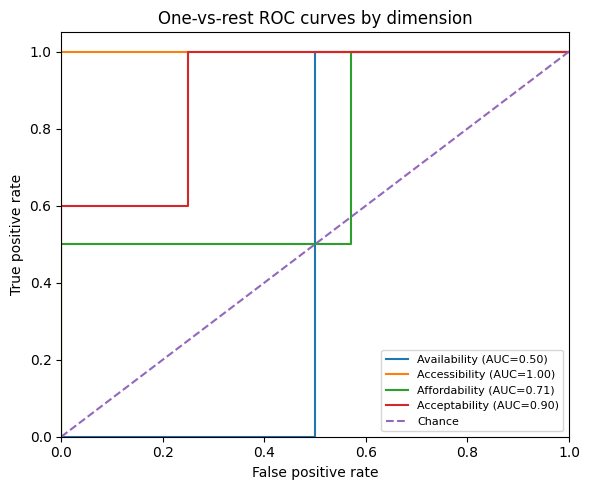

In [72]:
# ============================================================
# Plot ROC curves by dimension
# ============================================================

fig, ax = plt.subplots(figsize=(6, 5))

for dim in DIM_ORDER:
    y_true = eval_topics["manual_label_set"].apply(
        lambda labels: int(dim in set(labels))
    )

    y_score = eval_topics[f"{dim}_p"]

    if y_true.nunique() < 2:
        continue

    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    ax.plot(fpr, tpr, label=f"{dim} (AUC={roc_auc:.2f})")

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("One-vs-rest ROC curves by dimension")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

Overall ROC-AUC

In [79]:
# ============================================================
# Overall ROC-AUC summaries
# ============================================================

from sklearn.metrics import roc_auc_score

# Build multilabel y_true and y_score matrices
y_true_mat = np.column_stack([
    eval_topics["manual_label_set"].apply(lambda labels: int(dim in set(labels))).to_numpy()
    for dim in DIM_ORDER
])

y_score_mat = eval_topics[[f"{dim}_p" for dim in DIM_ORDER]].to_numpy()

# Macro-average:
# average the per-dimension ROC-AUC values, ignoring dimensions where AUC is undefined
macro_auc = roc_auc_df["roc_auc"].mean(skipna=True)

# Micro-average:
# flatten all one-vs-rest decisions into a single vector
# requires at least one positive and one negative overall
y_true_flat = y_true_mat.ravel()
y_score_flat = y_score_mat.ravel()

if len(np.unique(y_true_flat)) < 2:
    micro_auc = np.nan
else:
    micro_auc = roc_auc_score(y_true_flat, y_score_flat)

overall_roc_auc_df = pd.DataFrame([
    {
        "metric": "macro_average",
        "roc_auc": macro_auc,
        "description": "Mean of per-dimension ROC-AUC values; each dimension weighted equally.",
    },
    {
        "metric": "micro_average",
        "roc_auc": micro_auc,
        "description": "ROC-AUC after flattening all dimension-topic decisions; more frequent labels contribute more.",
    },
])

overall_roc_auc_df

,metric,roc_auc,description
0,macro_average,0.778571,Mean of per-dimension ROC-AUC values; each dim...
1,micro_average,0.796296,ROC-AUC after flattening all dimension-topic d...


### Merge Back with Reviews Dataframe and Save

In [73]:
# ============================================================
# Convert manual label sets into model-like manual prediction columns
# ============================================================

def unpack_manual_labels(label_set, max_main_labels=3):
    """
    Convert manual_label_set into model-like columns:
    manual_pred_dim, manual_pred_dim2, manual_pred_dim3.

    If a topic has more than 3 manual labels, extra labels are stored
    separately in manual_extra_dims. This preserves broad-topic information
    without breaking the model-like column structure.
    """
    if isinstance(label_set, (list, tuple, set)):
        labels = list(label_set)
    elif pd.isna(label_set):
        labels = []
    elif isinstance(label_set, str):
        # Handles cases where tuples were reloaded from CSV as strings
        cleaned = (
            label_set.replace("(", "")
            .replace(")", "")
            .replace("[", "")
            .replace("]", "")
            .replace("'", "")
            .replace('"', "")
        )
        labels = [x.strip() for x in cleaned.split(",") if x.strip()]
    else:
        labels = []

    # Preserve your defined dimension order
    labels = [dim for dim in DIM_ORDER if dim in labels]

    out = {
        "manual_pred_dim": labels[0] if len(labels) >= 1 else np.nan,
        "manual_pred_dim2": labels[1] if len(labels) >= 2 else np.nan,
        "manual_pred_dim3": labels[2] if len(labels) >= 3 else np.nan,
        "manual_extra_dims": tuple(labels[3:]) if len(labels) > 3 else tuple(),
    }

    return pd.Series(out)


manual_pred_cols = validation_topics["manual_label_set"].apply(unpack_manual_labels)

validation_topics = pd.concat(
    [validation_topics, manual_pred_cols],
    axis=1
)

validation_topics[
    [
        "Topic",
        "manual_label_set",
        "manual_pred_dim",
        "manual_pred_dim2",
        "manual_pred_dim3",
        "manual_extra_dims",
        "manual_n_labels",
        "manual_label_status",
    ]
].head()

,Topic,manual_label_set,manual_pred_dim,manual_pred_dim2,manual_pred_dim3,manual_extra_dims,manual_n_labels,manual_label_status
0,0,"(Acceptability,)",Acceptability,NaN,NaN,(),1,valid
1,1,(),NaN,NaN,NaN,(),0,unclear
2,2,(),NaN,NaN,NaN,(),0,unclear
3,3,"(Affordability,)",Affordability,NaN,NaN,(),1,valid
4,4,"(Affordability,)",Affordability,NaN,NaN,(),1,valid


In [77]:
# ============================================================
# Merge derived manual/model label fields back onto reviews
# ============================================================

reviews_with_validation = reviews.copy()
reviews_with_validation["Topic"] = reviews_with_validation["topic"].astype("Int64")

derived_merge_cols = [
    "Topic",
    
    # Manual validation status
    "manual_topic_status",
    "manual_invalid_reason",
    "manual_notes",
    "last_updated",
    "manual_scored",
    "manual_is_valid",
    "manual_is_invalid",
    "manual_needs_review",

    # Raw manual 0-3 scores
    "manual_Availability",
    "manual_Accessibility",
    "manual_Accommodation",
    "manual_Affordability",
    "manual_Acceptability",

    # Derived manual label information
    "manual_max_score",
    "manual_n_labels",
    "manual_label_status",

    # Model-like manual predicted dimension columns
    "manual_pred_dim",
    "manual_pred_dim2",
    "manual_pred_dim3",
    "manual_extra_dims",

    # Optional: keep full set for analysis/debugging
    "manual_label_set",

    # Optional model diagnostic columns
    "model_n_labels",
]

derived_merge_cols = [
    col for col in derived_merge_cols
    if col in validation_topics.columns
]

reviews_with_validation = reviews_with_validation.merge(
    validation_topics[derived_merge_cols],
    on="Topic",
    how="left",
    validate="many_to_one",
)

reviews_with_validation = reviews_with_validation.drop(columns=["Topic"])

reviews_with_validation.to_csv(REVIEWS_VALIDATION_OUTPUT_PATH, index=False)

print("Saved review-level dataframe with manual validation to:")
print(REVIEWS_VALIDATION_OUTPUT_PATH)

Saved review-level dataframe with manual validation to:
data\manual_validation\reviews_with_manual_validation.csv


In [78]:
reviews_with_validation.head()

,address,categoryName,cid,city,countryCode,error,fid,isAdvertisement,isLocalGuide,language,...,manual_Acceptability,manual_max_score,manual_n_labels,manual_label_status,manual_pred_dim,manual_pred_dim2,manual_pred_dim3,manual_extra_dims,manual_label_set,model_n_labels
0,"3926 Western Blvd, Raleigh, NC 27607",Grocery store,9079003590392506921,Raleigh,US,NaN,0x89acf5b06a500239:0x7dff19a9afd76a29,False,False,en,...,NaN,NaN,0.0,not_scored,NaN,NaN,NaN,(),(),3.0
1,"3926 Western Blvd, Raleigh, NC 27607",Grocery store,9079003590392506921,Raleigh,US,NaN,0x89acf5b06a500239:0x7dff19a9afd76a29,False,False,en,...,NaN,NaN,0.0,not_scored,NaN,NaN,NaN,(),(),3.0
2,"3926 Western Blvd, Raleigh, NC 27607",Grocery store,9079003590392506921,Raleigh,US,NaN,0x89acf5b06a500239:0x7dff19a9afd76a29,False,True,en,...,NaN,NaN,0.0,not_scored,NaN,NaN,NaN,(),(),2.0
3,"3926 Western Blvd, Raleigh, NC 27607",Grocery store,9079003590392506921,Raleigh,US,NaN,0x89acf5b06a500239:0x7dff19a9afd76a29,False,True,en,...,2.0,3.0,1.0,valid,Affordability,NaN,NaN,(),"(Affordability,)",1.0
4,"3926 Western Blvd, Raleigh, NC 27607",Grocery store,9079003590392506921,Raleigh,US,NaN,0x89acf5b06a500239:0x7dff19a9afd76a29,False,False,en,...,NaN,NaN,0.0,not_scored,NaN,NaN,NaN,(),(),1.0
